# Tutorial: from oscillation probabilities to numbers of events

## Solutions

In this notebook we use a **simple model of the number of $\nu_e$ appearance events** at T2K, Hyper-K, NOvA and DUNE
(see `docs/number_of_events_summary.pdf`):

$$
N = P(\nu_\mu\to\nu_e;\,E_0, L)\;\sigma_{CC}(E_0)\;\Phi\;\mathrm{POT}\;N_T
  \;=\; \underbrace{N_{P=1}}_{\text{fixed for each experiment}}\;\times\;P(E_0) .
$$

This is the number of $\nu_e$ ($\bar\nu_e$) **charged-current interactions** in the detector, under three simple
assumptions: the beam is a pure $\nu_\mu$ ($\bar\nu_\mu$) beam, all neutrinos have the same energy $E_0$, and the detector
sees every interaction (efficiency $= 100\,\%$). In Section 4 we compare it with the numbers predicted by the
collaborations, which include the real detector and beam.

Everything except $P$ is fixed by the experiment (beam, detector, exposure). So **the number of events changes only
through the oscillation probability**: to see how $N$ depends on $\delta_{CP}$, on the mass ordering or on $\theta_{23}$,
we only need to recompute $P$ at the beam energy $E_0$.

Plan:
1. The inputs and the function `n_events`
2. Examples
3. Exercises: numbers of events, bi-probability and bi-event plots, sensitivity to CP violation
4. How realistic is the simple model? Comparison with the experiments' predictions

In [25]:
import numpy as np
import matplotlib.pyplot as plt

from nuosc import NeutrinoOscillator
from nuosc.plotting import set_style

SET_STYLE = True     # True: nuosc style (latex_style -> SciencePlots -> default); False: keep your own matplotlib settings
c = set_style(SET_STYLE)

plot style: latex_style


## 1. The inputs and the function

For each experiment and beam mode (`"nu"`: neutrino beam, `"nubar"`: antineutrino beam) we need only two numbers,
taken from the table of `docs/number_of_events_summary.pdf`:

* `E0`: the beam energy [GeV] at which $P$ is evaluated;
* `N1`: $N_{P=1} = \sigma_{CC}(E_0)\,\Phi\,\mathrm{POT}\,N_T$, the number of CC interactions if every $\nu_\mu$ became a $\nu_e$.

The baseline $L$ and the matter density are those of the experiment configuration in `nuosc`
(`NeutrinoOscillator.from_experiment`).

In [26]:
INPUTS = {
    #          beam mode: E0 [GeV], N_{P=1}
    "T2K":    {"nu": dict(E0=0.57, N1=994),   "nubar": dict(E0=0.55, N1=251)},
    "HyperK": {"nu": dict(E0=0.57, N1=37329), "nubar": dict(E0=0.55, N1=25809)},
    "NOvA":   {"nu": dict(E0=1.80, N1=5792),  "nubar": dict(E0=1.79, N1=975)},
    "DUNE":   {"nu": dict(E0=2.31, N1=47441), "nubar": dict(E0=2.27, N1=17384)},
}
EXPERIMENTS = list(INPUTS)


def probability(exp, beam, ordering="NO", **params):
    # P(numu -> nue) (beam = "nu") or P(numubar -> nuebar) (beam = "nubar") at the beam energy E0
    osc = NeutrinoOscillator.from_experiment(exp, ordering=ordering, antineutrino=(beam == "nubar"), **params)
    return float(osc.matter("mu", "e", E=INPUTS[exp][beam]["E0"]))


def n_events(exp, beam, ordering="NO", **params):
    # expected number of nue (nuebar) CC interactions = N_{P=1} * P(E0)
    return INPUTS[exp][beam]["N1"] * probability(exp, beam, ordering, **params)

`**params` are any oscillation parameters accepted by `NeutrinoOscillator` (`delta_cp` in degrees, `s2_23`, `dm2_31`, ...);
those not given are at the NuFIT 6.0 best fit of the chosen ordering.

## 2. Examples

In [27]:
# number of events at the NuFIT 6.0 best fit (NO: delta_CP = 212 deg)
print(f"T2K, nu beam:    N = {n_events('T2K', 'nu'):.1f}")
print(f"T2K, nubar beam: N = {n_events('T2K', 'nubar'):.1f}")

# the same with another delta_CP: only P changes
for d in (0, 90, 180, 270):
    print(f"delta_CP = {d:3d} deg: P = {probability('T2K', 'nu', delta_cp=d):.4f},  N = {n_events('T2K', 'nu', delta_cp=d):.1f}")

# inverted ordering (its own NuFIT best fit) and another theta_23
print(f"T2K, nu beam, IO:            N = {n_events('T2K', 'nu', ordering='IO'):.1f}")
print(f"T2K, nu beam, sin2_23 = 0.6: N = {n_events('T2K', 'nu', s2_23=0.6):.1f}")

T2K, nu beam:    N = 53.0
T2K, nubar beam: N = 7.9
delta_CP =   0 deg: P = 0.0449,  N = 44.6
delta_CP =  90 deg: P = 0.0318,  N = 31.6
delta_CP = 180 deg: P = 0.0461,  N = 45.8
delta_CP = 270 deg: P = 0.0592,  N = 58.9
T2K, nu beam, IO:            N = 56.7
T2K, nu beam, sin2_23 = 0.6: N = 64.8


The statistical uncertainty on a number of events is $\sqrt N$:

In [28]:
N = n_events("NOvA", "nu")
print(f"NOvA nu beam: N = {N:.1f} +- {np.sqrt(N):.1f}  (relative error {1 / np.sqrt(N):.0%})")

NOvA nu beam: N = 316.5 +- 17.8  (relative error 6%)


## 3. Exercises

**Exercise 1: number of events.** For the four experiments, compute the number of events in the $\nu$ and $\bar\nu$ beams
at the NuFIT 6.0 best fit, for NO and IO. Which experiment has the most events? In which beam?

**Exercise 2: bi-probability plot.** Fix all oscillation parameters to the NuFIT 6.0 normal-ordering best fit
(`NUFIT_NO` in `nuosc.parameters`) and compare two hypotheses that differ **only in the sign of $\Delta m^2_{31}$**:
NO ($\Delta m^2_{31}>0$) and IO ($\Delta m^2_{31}\to-\Delta m^2_{31}$). For each experiment and hypothesis, scan
$\delta_{CP}$ from $0$ to $360°$ and plot $P(\bar\nu_\mu\to\bar\nu_e)$ (y) against $P(\nu_\mu\to\nu_e)$ (x) (one panel
per experiment, one colour per hypothesis). Mark $\delta_{CP}=0$ and $90°$ on each ellipse. Then mark, with a single
black point, the "true" universe: NO with $\delta_{CP}=212°$ (the NuFIT best fit).
*Hint:* `probability(exp, "nu", "IO", **dict(NUFIT_NO, dm2_31=-NUFIT_NO["dm2_31"], delta_cp=d))`.

**Exercise 3: bi-event plot.** The same with the numbers of events $N_{\bar\nu}$ against $N_\nu$. The black point is now
a pseudo-measurement (Asimov data set): the expected numbers of events in the true universe, with error bars
$\pm\sqrt N$. Why do the bi-probability and bi-event plots have the same shape? Which points of the two ellipses are
compatible with the measurement? Which experiments can tell NO from IO, if the truth is NO with $\delta_{CP}=212°$?

**Exercise 4: sensitivity to CP violation.** For a true value of $\delta_{CP}$, the $\chi^2$ to reject CP conservation is
$$
\Delta\chi^2(\delta_{CP}) = \min_{\delta'\in\{0,\,180°\}} \sum_{\nu,\bar\nu}
\frac{\left[N(\delta_{CP}) - N(\delta')\right]^2}{N(\delta_{CP})},
$$
and the significance is $\sqrt{\Delta\chi^2}$ (in units of $\sigma$). Plot $\sqrt{\Delta\chi^2}$ against the true $\delta_{CP}$
for the four experiments, NO and IO. For which values of $\delta_{CP}$ is the sensitivity largest, and why is it zero at
$0$ and $180°$? Which experiments reach $3\sigma$ and $5\sigma$?

**Exercise 5: systematics.** Add a normalization uncertainty of 5 % on each sample, i.e. replace the denominator with
$N(\delta_{CP}) + (0.05\,N(\delta_{CP}))^2$, and compare with Exercise 4. Which experiments are affected, and why?

### Exercise 1: number of events

In [29]:
print(f"{'':7s} {'NO: nu':>8s} {'nubar':>8s} {'IO: nu':>9s} {'nubar':>8s}")
for exp in EXPERIMENTS:
    row = [n_events(exp, b, o) for o in ("NO", "IO") for b in ("nu", "nubar")]
    print(f"{exp:7s} {row[0]:8.1f} {row[1]:8.1f} {row[2]:9.1f} {row[3]:8.1f}")

          NO: nu    nubar    IO: nu    nubar
T2K         53.0      7.9      56.7      9.9
HyperK    1989.3    814.5    2127.6   1013.5
NOvA       316.5     24.3     267.8     44.2
DUNE      3501.9    310.7    1741.8    978.4


Hyper-K and DUNE collect thousands of events (large detectors and long exposures), T2K and NOvA tens to a hundred.
The $\bar\nu$ beam has fewer events: smaller cross section and, at DUNE, matter suppression for NO.

### Exercise 2: bi-probability plot

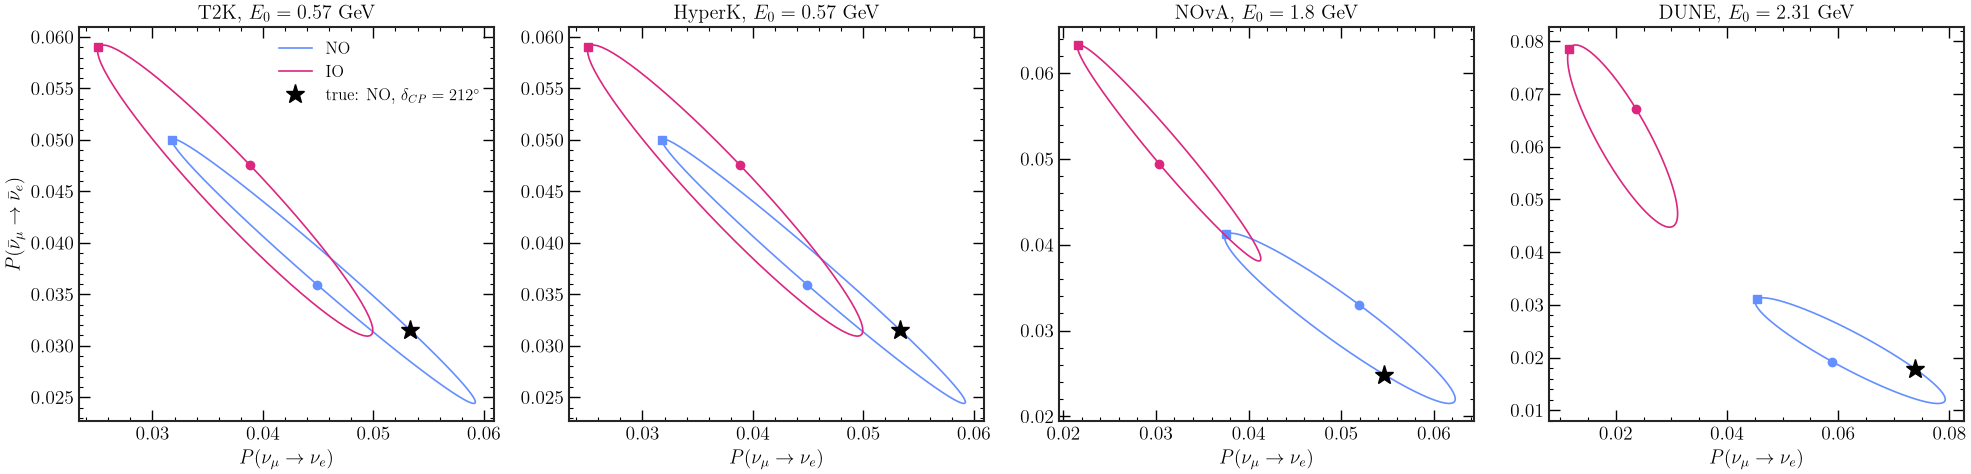

In [30]:
from nuosc.parameters import NUFIT_NO

ORDERINGS = ("NO", "IO")
# two hypotheses: everything at the NuFIT 6.0 NO best fit, only the sign of dm2_31 changes
HYPOTHESES = {"NO": dict(NUFIT_NO), "IO": dict(NUFIT_NO, dm2_31=-NUFIT_NO["dm2_31"])}
TRUE = dict(hyp="NO", delta_cp=212)          # the "true" universe (Asimov point)
deltas = np.arange(0, 361, 5)

def at(func, exp, hyp, delta_cp):
    # (nu, nubar) values of func (probability or n_events) for a hypothesis and a value of delta_CP
    return np.array([func(exp, b, hyp, **dict(HYPOTHESES[hyp], delta_cp=delta_cp)) for b in ("nu", "nubar")])

def scan(func, exp, hyp):
    # ellipse: (nu, nubar) values along the delta_CP scan
    return np.array([at(func, exp, hyp, d) for d in deltas])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, exp in zip(axes, EXPERIMENTS):
    for i, h in enumerate(ORDERINGS):
        P = scan(probability, exp, h)
        ax.plot(P[:, 0], P[:, 1], color=c[i], label=h)
        ax.plot(*P[deltas == 0][0], "o", color=c[i])
        ax.plot(*P[deltas == 90][0], "s", color=c[i])
    ax.plot(*at(probability, exp, TRUE["hyp"], TRUE["delta_cp"]), "*", ms=14, color="k", zorder=5,
            label=r"true: NO, $\delta_{CP}=212^\circ$")
    ax.set_title(f"{exp}, $E_0 = {INPUTS[exp]['nu']['E0']}$ GeV")
    ax.set_xlabel(r"$P(\nu_\mu\to\nu_e)$")
axes[0].set_ylabel(r"$P(\bar\nu_\mu\to\bar\nu_e)$")
axes[0].legend()
plt.tight_layout()
plt.show()

Circles: $\delta_{CP}=0$, squares: $90°$, black star: the true point. $\delta_{CP}$ moves the point along an ellipse
($\nu$ up and $\bar\nu$ down, or the reverse). Since all other parameters are the same, the distance between the two
ellipses is due only to the sign of $\Delta m^2_{31}$, i.e. to the matter effect, which grows with the baseline: the
ellipses overlap at T2K/Hyper-K (295 km) and are well separated at DUNE (1300 km).

### Exercise 3: bi-event plot

T2K     closest point of the NO ellipse: chi2 =    0.0  ( 0.0 sigma)
T2K     closest point of the IO ellipse: chi2 =    0.2  ( 0.5 sigma)
HyperK  closest point of the NO ellipse: chi2 =    0.0  ( 0.0 sigma)
HyperK  closest point of the IO ellipse: chi2 =    7.8  ( 2.8 sigma)
NOvA    closest point of the NO ellipse: chi2 =    0.0  ( 0.0 sigma)
NOvA    closest point of the IO ellipse: chi2 =   25.8  ( 5.1 sigma)
DUNE    closest point of the NO ellipse: chi2 =    0.0  ( 0.0 sigma)
DUNE    closest point of the IO ellipse: chi2 = 1923.0  (43.9 sigma)


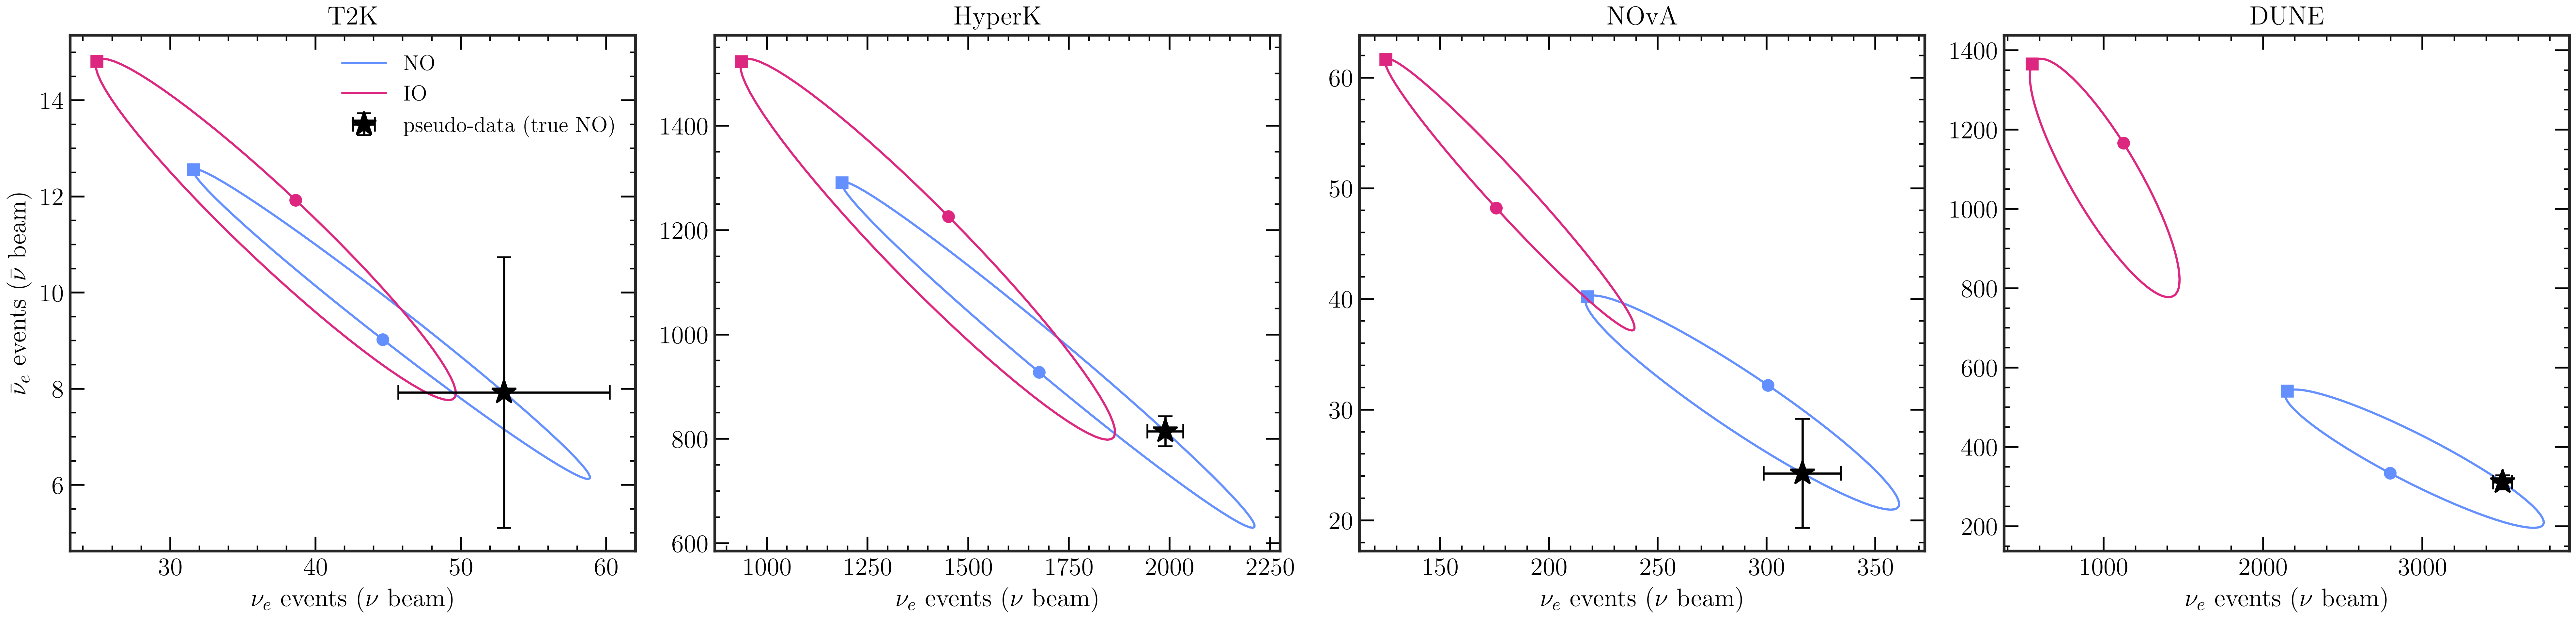

In [36]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), dpi = 400)
for ax, exp in zip(axes, EXPERIMENTS):
    for i, h in enumerate(ORDERINGS):
        N = scan(n_events, exp, h)
        ax.plot(N[:, 0], N[:, 1], color=c[i], label=h)
        ax.plot(*N[deltas == 0][0], "o", color=c[i])
        ax.plot(*N[deltas == 90][0], "s", color=c[i])
    data = at(n_events, exp, TRUE["hyp"], TRUE["delta_cp"])
    ax.errorbar(*data, xerr=np.sqrt(data[0]), yerr=np.sqrt(data[1]), fmt="*", ms=14, color="k", capsize=4,
                zorder=5, label="pseudo-data (true NO)")
    # how far is the measurement from each ellipse? smallest chi^2 = sum (N_data - N)^2 / N_data
    fine = np.arange(0, 360, 1)
    for h in ORDERINGS:
        chi2 = min(np.sum((data - at(n_events, exp, h, d)) ** 2 / data) for d in fine)
        print(f"{exp:7s} closest point of the {h} ellipse: chi2 = {chi2:6.1f}  ({np.sqrt(chi2):4.1f} sigma)")
    ax.set_title(exp)
    ax.set_xlabel(r"$\nu_e$ events ($\nu$ beam)")
axes[0].set_ylabel(r"$\bar\nu_e$ events ($\bar\nu$ beam)")
axes[0].legend()
plt.tight_layout()
plt.show()

The shapes are the same as in the bi-probability plot because $N = N_{P=1}\times P$: each axis is the probability
multiplied by a constant. The pseudo-data lie on the NO ellipse by construction; the question is how far they are from
the IO ellipse, in units of the statistical error (printed above: smallest $\chi^2$ over $\delta_{CP}$ on each ellipse).

* **T2K**: the error bars cover a large part of both ellipses (the closest IO point is $0.5\sigma$ away): T2K cannot
  tell NO from IO, and the ordering and $\delta_{CP}$ are degenerate.
* **Hyper-K**: the error bars are small, but at 295 km the two ellipses overlap; the closest IO point is about
  $3\sigma$ away (statistics only).
* **NOvA**: the closest IO point is about $5\sigma$ away. This is for a perfect detector: with the normalization of
  Section 4 ($r\approx 0.4$--$0.5$) it becomes about $3.4\sigma$.
* **DUNE**: the IO ellipse is far away (more than $40\sigma$): DUNE determines the mass ordering.

The answer depends on where the truth is. Repeat the plot with `TRUE = dict(hyp="NO", delta_cp=90)`: the NO point at
$\delta_{CP}=90°$ is close to the IO ellipse, and NOvA and Hyper-K lose most of their sensitivity to the ordering.


### Exercise 4: sensitivity to CP violation (statistics only)

T2K     NO: max   2.5 sigma, delta_CP range above 3 sigma:   0%
T2K     IO: max   2.3 sigma, delta_CP range above 3 sigma:   0%
HyperK  NO: max  17.4 sigma, delta_CP range above 3 sigma:  87%
HyperK  IO: max  16.2 sigma, delta_CP range above 3 sigma:  87%
NOvA    NO: max   4.4 sigma, delta_CP range above 3 sigma:  46%
NOvA    IO: max   4.1 sigma, delta_CP range above 3 sigma:  39%
DUNE    NO: max  18.1 sigma, delta_CP range above 3 sigma:  88%
DUNE    IO: max  16.9 sigma, delta_CP range above 3 sigma:  87%


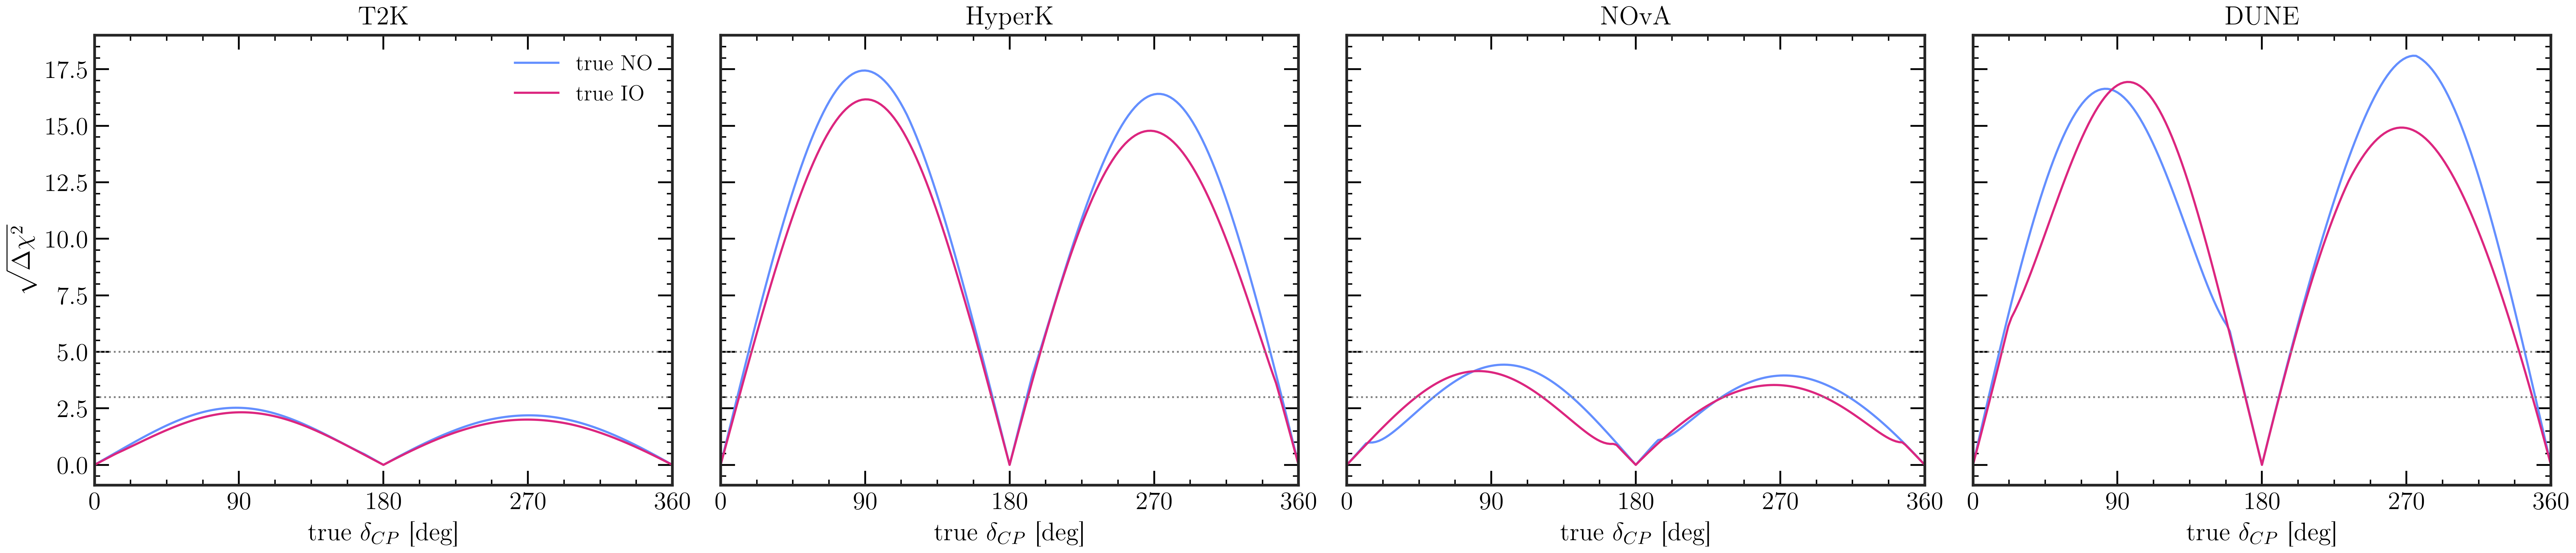

In [38]:
def counts(exp, ordering, delta_cp):
    return np.array([n_events(exp, b, ordering, delta_cp=delta_cp) for b in ("nu", "nubar")])

def cpv_sensitivity(exp, ordering, f=0.0, deltas=np.arange(0, 361, 2)):
    # sqrt(Delta chi^2) to reject delta_CP = 0 and 180 deg, as a function of the true delta_CP
    N_cp = [counts(exp, ordering, d0) for d0 in (0, 180)]           # CP-conserving predictions
    out = []
    for d in deltas:
        N_true = counts(exp, ordering, d)
        var = N_true + (f * N_true) ** 2                              # statistical (+ normalization) variance
        chi2 = min(np.sum((N_true - N0) ** 2 / var) for N0 in N_cp)
        out.append(np.sqrt(chi2))
    return deltas, np.array(out)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True, dpi = 400)
for ax, exp in zip(axes, EXPERIMENTS):
    for i, o in enumerate(ORDERINGS):
        d, s = cpv_sensitivity(exp, o)
        ax.plot(d, s, color=c[i], label=f"true {o}")
        print(f"{exp:7s} {o}: max {s.max():5.1f} sigma, delta_CP range above 3 sigma: {np.mean(s > 3):4.0%}")
    for z in (3, 5):
        ax.axhline(z, color="gray", ls=":", lw=1)
    ax.set_xticks([0, 90, 180, 270, 360])
    ax.set_xlim(0, 360)
    ax.set_title(exp)
    ax.set_xlabel(r"true $\delta_{CP}$ [deg]")
axes[0].set_ylabel(r"$\sqrt{\Delta\chi^2}$")
axes[0].legend()
plt.tight_layout()
plt.show()

The sensitivity is zero at $\delta_{CP}=0$ and $180°$ (the true value *is* CP conserving) and largest near $90°$ and $270°$,
where $\sin\delta_{CP}$, and so the difference between $\nu$ and $\bar\nu$, is maximal. With its current exposure T2K
stays below $3\sigma$; NOvA reaches about $4\sigma$ near $\delta_{CP}=270°$; Hyper-K and DUNE exceed $5\sigma$ over a large
part of the $\delta_{CP}$ range (statistics only). Remember that these are the numbers of a perfect detector: Section 4
shows how optimistic they are.

### Exercise 5: with a 5 % normalization uncertainty

T2K     NO: max   2.5 sigma (stat. only) ->   2.4 sigma (with 5% normalization)
T2K     IO: max   2.3 sigma (stat. only) ->   2.2 sigma (with 5% normalization)
HyperK  NO: max  17.4 sigma (stat. only) ->   8.7 sigma (with 5% normalization)
HyperK  IO: max  16.2 sigma (stat. only) ->   7.7 sigma (with 5% normalization)
NOvA    NO: max   4.4 sigma (stat. only) ->   3.7 sigma (with 5% normalization)
NOvA    IO: max   4.1 sigma (stat. only) ->   3.6 sigma (with 5% normalization)
DUNE    NO: max  18.1 sigma (stat. only) ->   9.3 sigma (with 5% normalization)
DUNE    IO: max  16.9 sigma (stat. only) ->   9.4 sigma (with 5% normalization)


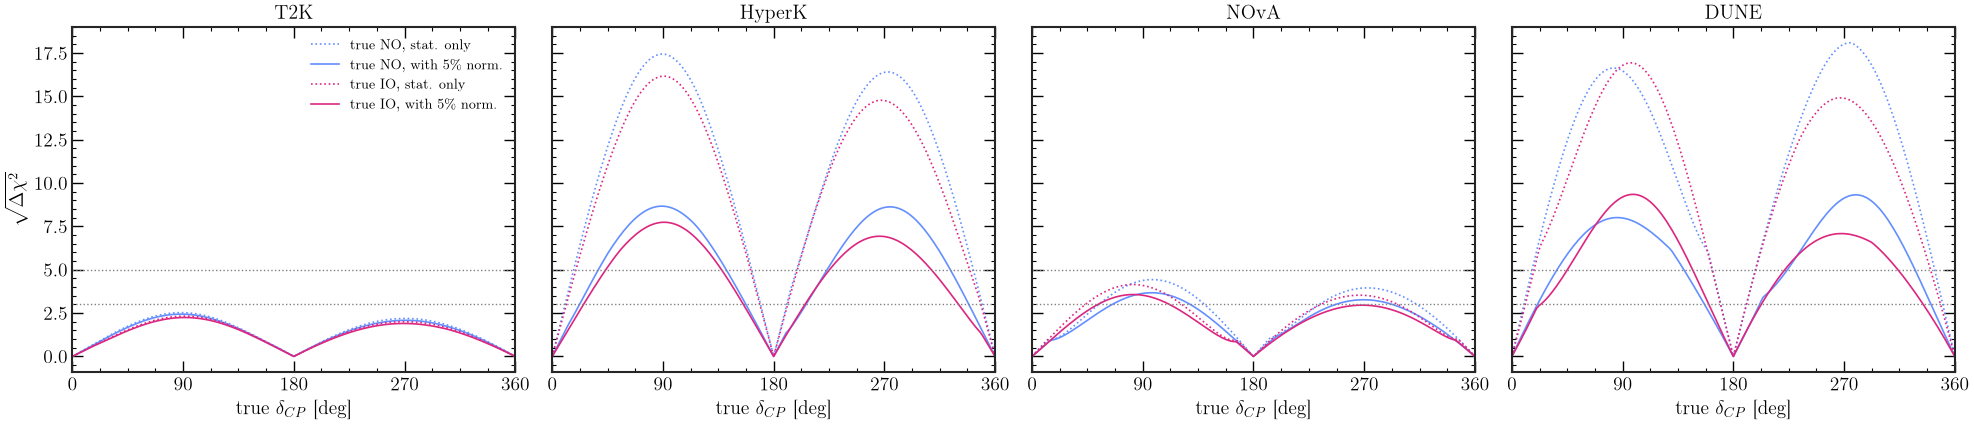

In [33]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5), sharey=True)
for ax, exp in zip(axes, EXPERIMENTS):
    for i, o in enumerate(ORDERINGS):
        d, s0 = cpv_sensitivity(exp, o, f=0.0)
        d, s5 = cpv_sensitivity(exp, o, f=0.05)
        ax.plot(d, s0, color=c[i], ls=":", label=f"true {o}, stat. only")
        pct = r"\%" if plt.rcParams["text.usetex"] else "%"
        ax.plot(d, s5, color=c[i], label=f"true {o}, with 5{pct} norm.")
        print(f"{exp:7s} {o}: max {s0.max():5.1f} sigma (stat. only) -> {s5.max():5.1f} sigma (with 5% normalization)")
    for z in (3, 5):
        ax.axhline(z, color="gray", ls=":", lw=1)
    ax.set_xticks([0, 90, 180, 270, 360])
    ax.set_xlim(0, 360)
    ax.set_title(exp)
    ax.set_xlabel(r"true $\delta_{CP}$ [deg]")
axes[0].set_ylabel(r"$\sqrt{\Delta\chi^2}$")
axes[0].legend(fontsize="small")
plt.tight_layout()
plt.show()

The normalization uncertainty matters when $fN$ is comparable to $\sqrt N$, i.e. for $N \gtrsim 1/f^2 = 400$ events.
T2K (tens of events) is limited by statistics and barely changes; NOvA (about 300 events in the $\nu$ beam) loses a
little; Hyper-K and DUNE (thousands of events) become limited by the systematic uncertainty, and their maximum
sensitivity drops by about a factor of two.

## 4. How realistic is the simple model? Comparison with the experiments' predictions

The collaborations publish the number of $\nu_e$ ($\bar\nu_e$) appearance events expected in their analyses, computed
with full simulations of the beam, of the cross sections and of the detector. Each prediction is given for a specific set
of oscillation parameters, so we evaluate our formula at the same parameters and take the ratio
$$
r = \frac{N_\text{published}}{N_{P=1}\,P(E_0)} .
$$
If our model were exact, $r$ would be 1.

In [34]:
def s2(sin2_2theta):
    # sin^2(theta) from sin^2(2 theta), first octant
    return (1 - np.sqrt(1 - sin2_2theta)) / 2

REFERENCE = {
    # T2K, arXiv:2101.03779: Table XI total single-ring e-like events at delta_CP = -90 deg (74.4, 17.1) minus the
    # delta_CP-independent background (19.6, 12.3) from a fit of the four delta_CP values of the table; Table III parameters
    "T2K": dict(N=(54.8, 4.8), params=dict(s2_12=0.304, s2_13=0.0212, s2_23=0.528, delta_cp=270,
                                           dm2_21=7.53e-5, dm2_31=2.509e-3 + 7.53e-5)),
    # Hyper-K Design Report, arXiv:1805.04163, Tables XXXVI-XXXVII (10 years, 1:3 nu:nubar)
    "HyperK": dict(N=(1643, 1183), params=dict(s2_12=s2(0.8704), s2_13=s2(0.10), s2_23=0.5, delta_cp=0,
                                               dm2_21=7.6e-5, dm2_31=2.4e-3 + 7.6e-5)),
    # NOvA, arXiv:2509.04361, Table 2, at the NOvA best fit
    "NOvA": dict(N=(125.3, 18.9), params=dict(s2_12=s2(0.851), s2_13=s2(0.0851), s2_23=0.547, delta_cp=0.87 * 180,
                                              dm2_21=7.53e-5, dm2_31=2.441e-3 + 7.53e-5)),
    # DUNE, official GLoBES configuration (arXiv:2103.04797), signal at NuFIT 4.0 NO, delta_CP = 0
    "DUNE": dict(N=(2180, 438), params=dict(s2_12=np.sin(0.5903) ** 2, s2_13=np.sin(0.150) ** 2,
                                            s2_23=np.sin(0.866) ** 2, delta_cp=0, dm2_21=7.39e-5,
                                            dm2_31=2.451e-3 + 7.39e-5)),
}

RATIO = {}
print(f"{'':7s} {'beam':6s} {'published':>10s} {'N1 x P':>8s} {'ratio r':>8s}")
for exp, ref in REFERENCE.items():
    for k, beam in enumerate(("nu", "nubar")):
        N_simple = n_events(exp, beam, "NO", **ref["params"])
        RATIO[exp, beam] = ref["N"][k] / N_simple
        print(f"{exp:7s} {beam:6s} {ref['N'][k]:10.1f} {N_simple:8.1f} {RATIO[exp, beam]:8.2f}")

        beam    published   N1 x P  ratio r
T2K     nu           54.8     61.6     0.89
T2K     nubar         4.8      6.7     0.71
HyperK  nu         1643.0   2064.2     0.80
HyperK  nubar      1183.0   1155.6     1.02
NOvA    nu          125.3    290.5     0.43
NOvA    nubar        18.9     37.2     0.51
DUNE    nu         2180.0   3485.8     0.63
DUNE    nubar       438.0    409.4     1.07


The ratio $r$ is **not** an efficiency: it collects everything our formula leaves out.

* **Detector efficiency and analysis cuts** ($<1$): not every $\nu_e$ interaction is selected.
* **One energy instead of the spectrum.** We use $\Phi\,\sigma(E_0)\,P(E_0)$ instead of $\int \Phi(E)\,\sigma(E)\,P(E)\,dE$.
  For the $\nu$ beams this overestimates the rate by about 20 %: neutrinos far from $E_0$ have a smaller $P$.
  For the $\bar\nu$ beams the antineutrino cross section grows quickly with energy, so the high-energy part of the
  spectrum weighs more: the two effects roughly cancel at T2K and Hyper-K, and at DUNE the single energy even
  *underestimates* the rate, by about 40 %.
* **Cross sections**: the GLoBES tables are not the generators (NEUT, GENIE, ...) used by the collaborations.

So $r<1$ for the $\nu$ beams (efficiency and spectrum both reduce the rate), while for the $\bar\nu$ beams of Hyper-K
and DUNE the spectrum effect compensates the efficiency and $r\approx 1$ or even $>1$. The $\bar\nu$ ratios are not
explained by beam contamination: the published numbers used here are the $\bar\nu_\mu\to\bar\nu_e$ signal only.

With $r$ between 0.4 and 1.1, our numbers of events are those of a perfect detector: for NOvA about twice the published
ones, for the others within ~40 %. The significances of Exercises 4 and 5 are therefore **optimistic**, mostly for NOvA.
Multiplying each sample by its ratio $r$ gives an estimate closer to the experiments:

In [35]:
def max_sensitivity(exp, ordering, scale=(1.0, 1.0), f=0.0, deltas=np.arange(0, 361, 2)):
    # maximum sqrt(Delta chi^2) over the true delta_CP, with the nu and nubar samples multiplied by scale
    sc = np.array(scale)
    N_cp = [sc * counts(exp, ordering, d0) for d0 in (0, 180)]
    best = 0.0
    for d in deltas:
        N_true = sc * counts(exp, ordering, d)
        var = N_true + (f * N_true) ** 2
        best = max(best, np.sqrt(min(np.sum((N_true - N0) ** 2 / var) for N0 in N_cp)))
    return best

print(f"{'':7s} {'stat only: r = 1':>17s} {'x r':>6s} {'5% norm.: r = 1':>17s} {'x r':>6s}   (true NO)")
for exp in EXPERIMENTS:
    r = (RATIO[exp, "nu"], RATIO[exp, "nubar"])
    vals = [max_sensitivity(exp, "NO", s, f) for f in (0.0, 0.05) for s in ((1, 1), r)]
    print(f"{exp:7s} {vals[0]:17.1f} {vals[1]:6.1f} {vals[2]:17.1f} {vals[3]:6.1f}")

         stat only: r = 1    x r   5% norm.: r = 1    x r   (true NO)
T2K                   2.5    2.3               2.4    2.3
HyperK               17.4   16.2               8.7    8.6
NOvA                  4.4    2.9               3.7    2.7
DUNE                 18.1   15.7               9.3    9.4


With the ratios $r$, T2K and NOvA drop to $2.3\sigma$ and $2.9\sigma$: below $3\sigma$, as found by the experiments.
NOvA changes the most, because its $r\approx 0.4$–$0.5$ is the smallest. Hyper-K and DUNE stay far above $5\sigma$,
and with the 5 % normalization uncertainty they hardly change at all, because their sensitivity is limited by the
systematic uncertainty and not by the number of events.

Everything that depends only on $P$ (the bi-probability plot, the shape of the $\delta_{CP}$ dependence, the
degeneracies) is not affected. Only the absolute numbers of events and significances depend on $r$.